In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Brechas entre hombres y mujeres

Participación, desocupación e ingresos por sexo. Para que la serie sea comparable se usa la serie de
empalme (2010–2020) y la principal desde 2022, todas con el marco del CNPV 2018.

In [2]:
import dane_data as dd

por_sexo = pd.concat([
    dd.geih.serie_indicadores(range(2010, 2021), por="sexo", empalme=True),
    dd.geih.serie_indicadores(range(2022, 2026), por="sexo"),
], ignore_index=True).dropna(subset=["sexo"])
por_sexo.pivot(index="anio", columns="sexo", values=["tgp", "td"]).round(1)

tgp           td      
sexo Hombre Mujer Hombre Mujer
anio                          
2010   80.9  55.5    9.2  15.8
2011   81.2  56.0    8.4  14.6
2012   81.2  56.9    8.1  14.0
2013   80.3  56.1    7.6  12.9
2014   80.0  55.8    7.3  12.2
2015   79.8  56.0    7.0  12.1
2016   79.1  55.5    7.4  12.4
2017   78.7  55.1    7.4  12.6
2018   78.3  54.0    7.7  13.0
2019   77.3  53.2    8.5  14.0
2020   73.6  48.2   13.4  21.0
2022   76.5  51.8    9.0  14.3
2023   76.6  52.6    8.2  12.8
2024   76.4  52.4    8.2  12.7
2025   76.8  52.8    7.0  11.4

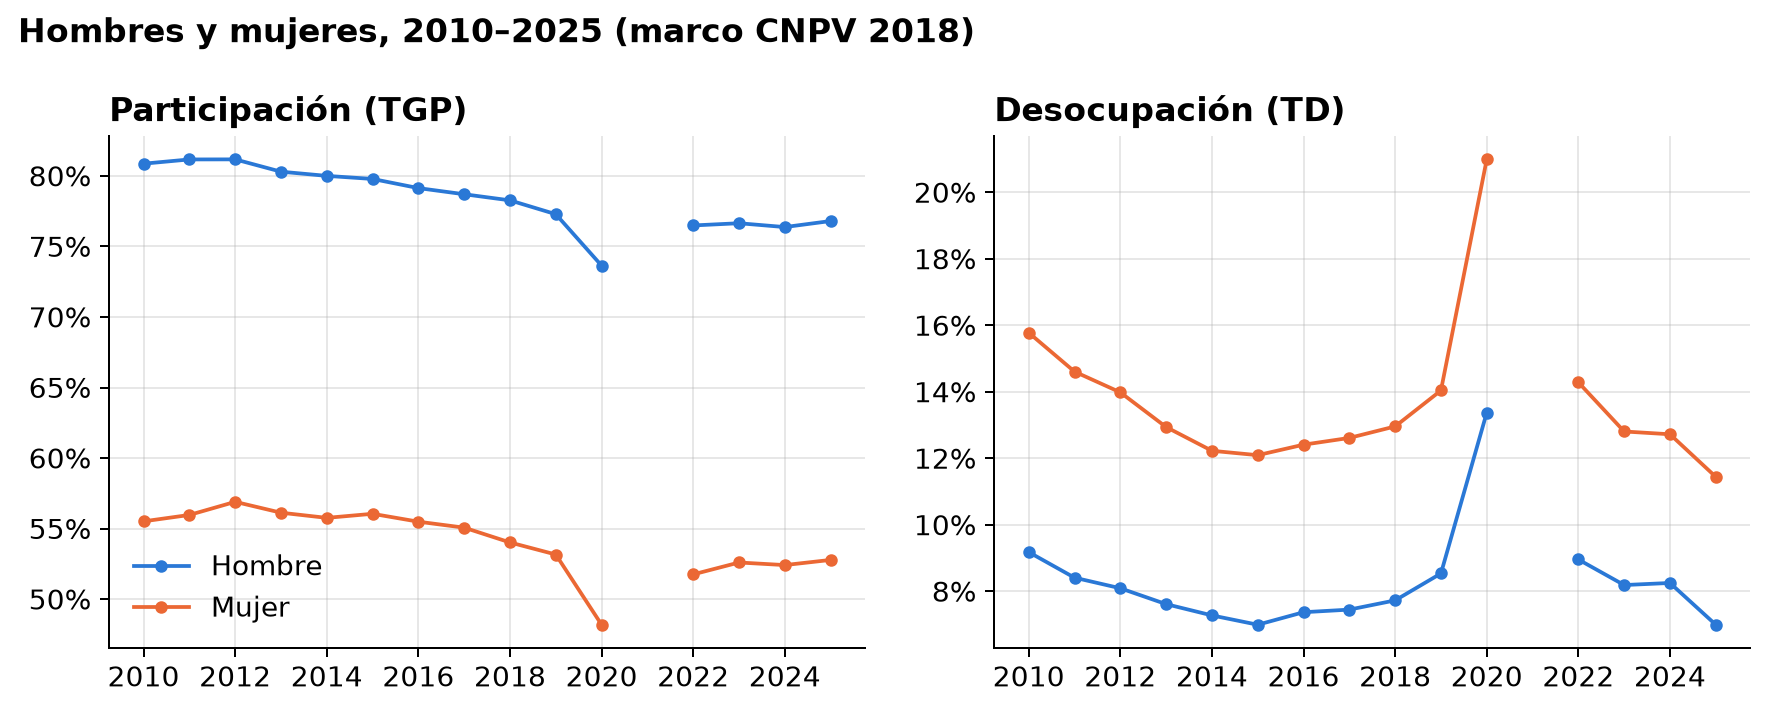

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, tasa, titulo in zip(axes, ["tgp", "td"], ["Participación (TGP)", "Desocupación (TD)"]):
    for sexo, d in por_sexo.groupby("sexo", observed=True):
        # Sin unir 2020 con 2022: 2021 no tiene el mismo marco
        for tramo in (d[d.anio <= 2020], d[d.anio >= 2022]):
            ax.plot(tramo["anio"], tramo[tasa], marker="o", ms=4, color="#2a78d6" if sexo == "Hombre" else "#eb6834",
                    label=sexo if tramo["anio"].min() == 2010 else None)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_title(titulo)
axes[0].legend()
fig.suptitle("Hombres y mujeres, 2010–2025 (marco CNPV 2018)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout();

`dropna` deja fuera a unas 700 personas de Putumayo de abril y mayo de 2017 que en el archivo de empalme del
DANE no tienen sexo (vea {doc}`../guia/diferencias`).

La brecha de participación es la más grande: en todos los años, la TGP de los hombres supera a la de las
mujeres en más de 20 puntos. Las mujeres que buscan trabajo, además, lo encuentran menos: su tasa de
desocupación es mayor.

## Brecha de ingresos

La mediana del ingreso laboral es el salario mínimo para hombres y mujeres (vea {doc}`salario_minimo`), así
que la brecha se ve mejor en la media. {dd}`geih.serie_tabla()` la calcula año por año:

In [4]:
media = dd.geih.serie_tabla(range(2022, 2026), por=["anio", "sexo"], variable="ingreso_laboral",
                            estadistico="media", poblacion="ocupado")
brecha = media.pivot(index="anio", columns="sexo", values="media")
brecha["brecha_%"] = 100 * (1 - brecha["Mujer"] / brecha["Hombre"])
brecha.round(1)

sexo,Hombre,Mujer,brecha_%
anio,,,
2022,1463013.4,1341858.7,8.3
2023,1653912.0,1500475.8,9.3
2024,1799783.6,1662354.1,7.6
2025,1945582.5,1807010.9,7.1


Una parte de la brecha viene de diferencias en educación, horas y ocupación. Dentro de cada nivel educativo:

In [5]:
por_educ = dd.geih.serie_tabla(2025, por=["nivel_educativo", "sexo"], variable="ingreso_laboral",
                               estadistico="media", poblacion="ocupado", dropna=True)
tabla = por_educ.pivot(index="nivel_educativo", columns="sexo", values="media")
tabla["brecha_%"] = 100 * (1 - tabla["Mujer"] / tabla["Hombre"])
tabla.round(1)

sexo,Hombre,Mujer,brecha_%
nivel_educativo,,,
Ninguno,825771.4,483284.2,41.5
Primaria,1136171.0,751966.7,33.8
Secundaria,1239697.5,870446.2,29.8
Media,1551712.3,1172720.3,24.4
Superior,3556466.5,2902284.9,18.4


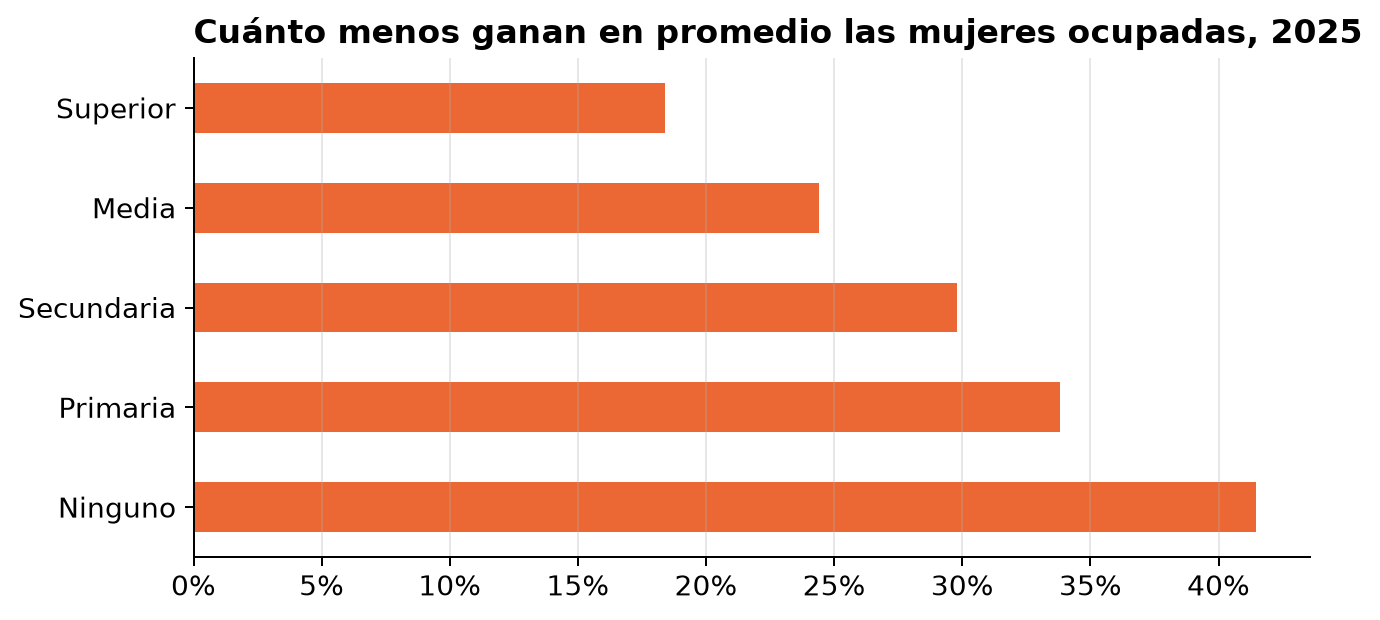

In [6]:
ax = tabla["brecha_%"].plot.barh(color="#eb6834", figsize=(8, 3.6))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("")
ax.set_title("Cuánto menos ganan en promedio las mujeres ocupadas, 2025")
ax.grid(axis="y", visible=False);

Dentro de cada nivel educativo la brecha es mucho mayor que en el total. La razón es la composición: las
mujeres ocupadas tienen, en promedio, más educación que los hombres ocupados.

In [7]:
comp = dd.geih.serie_tabla(2025, por=["sexo", "nivel_educativo"], estadistico="porcentaje",
                           poblacion="ocupado", dropna=True)
comp.pivot(index="nivel_educativo", columns="sexo", values="porcentaje").round(1)

sexo,Hombre,Mujer
nivel_educativo,,
Ninguno,3.6,2.1
Primaria,21.5,13.7
Secundaria,12.3,8.9
Media,35.1,33.5
Superior,27.5,41.8


```{seealso}
{doc}`../guia/tablas` explica `serie_tabla`, y {doc}`../guia/indicadores` las desagregaciones de
`serie_indicadores`.
```